# RehaPiano EXACT_FORCE – štatistická analýza

**Zadanie:**
1. základná štatistická analýza – porovnanie ľudí podľa veku (histogram po 10 rokoch), zdraví vs. pacienti;
2. určiť počet pacientov, ktorí slabo používajú jednu ruku;
3. navrhnúť analýzu trasu podľa jednotlivých prstov (či sa niektoré prsty trasú viac ako iné,
   či je rozdiel medzi trasom na jednotlivých prstoch u jedného človeka).

**Dáta:** všetci zdraví a pacienti s meraním EXACT_FORCE (počty v časti 1), cvičenie EXACT_FORCE – osoba stláča všetky prsty
a snaží sa udržať silu na cieľovej úrovni; 4 pokusy po 16 s, 1. pokus je skúšobný a nepoužíva sa, analyzuje sa úsek 3–15 s.
Každá osoba je zastúpená raz (priemer jej meraní).

**Upozornenie:** zdraví a pacienti mali cvičenie s rôznym `step_id` a pacienti sú starší.
Preto sa tremor pacientov porovnáva so zdravými vo veku ≥ 50 rokov.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap

# Make the project package importable from any folder of the repository.
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "rehapiano").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from rehapiano.common.config import ALPHA
from rehapiano.common.io.metadata import resolve_project_path
from rehapiano.common.preprocessing.pipeline import load_measurement_data
from rehapiano.exact_force.config import (CROP_END_S, CROP_START_S, EF_OUTPUT_DIR, ELEVATED_TREMOR_Z,
                                          GENERALIZED_MIN_FINGERS, LOCALIZED_MIN_FINGERS, REFERENCE_MIN_AGE,
                                          STATS_OUTPUT_DIR, TREMOR_BAND)
from rehapiano.exact_force.features.spectral import band_mask, compute_spectrogram
from rehapiano.exact_force.stats.hand_activity import weak_hand_patients, weak_hand_threshold

OUT = EF_OUTPUT_DIR
STATS = STATS_OUTPUT_DIR
attempts = pd.read_csv(OUT / "features_by_attempt_finger.csv")
wide = pd.read_csv(OUT / "dataset_wide.csv")
T = {path.stem: pd.read_csv(path) for path in sorted(STATS.glob("*.csv"))}

In [2]:
# Shared style: thin marks, recessive grid, validated colours.
GROUP_COLORS = {"control": "#2a78d6", "patient": "#eb6834"}
REFERENCE_COLOR = "#1c5cab"  # darker step of the control blue
FINGER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10,
})

SK_GROUP = {"control": "Zdraví", "patient": "Pacienti"}
SK_HAND = {"left": "Ľavá ruka", "right": "Pravá ruka"}
SK_HAND_SHORT = {"left": "ľavá", "right": "pravá"}
FINGERS = ["little", "ring", "middle", "index", "thumb"]
SK_FINGER = {"little": "malíček", "ring": "prstenník", "middle": "prostredník", "index": "ukazovák", "thumb": "palec"}
GROUPS, HANDS = ["control", "patient"], ["left", "right"]


def fmt(value, digits=1):
    """Slovak decimal comma."""
    return f"{value:.{digits}f}".replace(".", ",")

## 1. Vek: zdraví vs. pacienti

Každá osoba je započítaná raz, jeden stĺpec = 10 rokov.

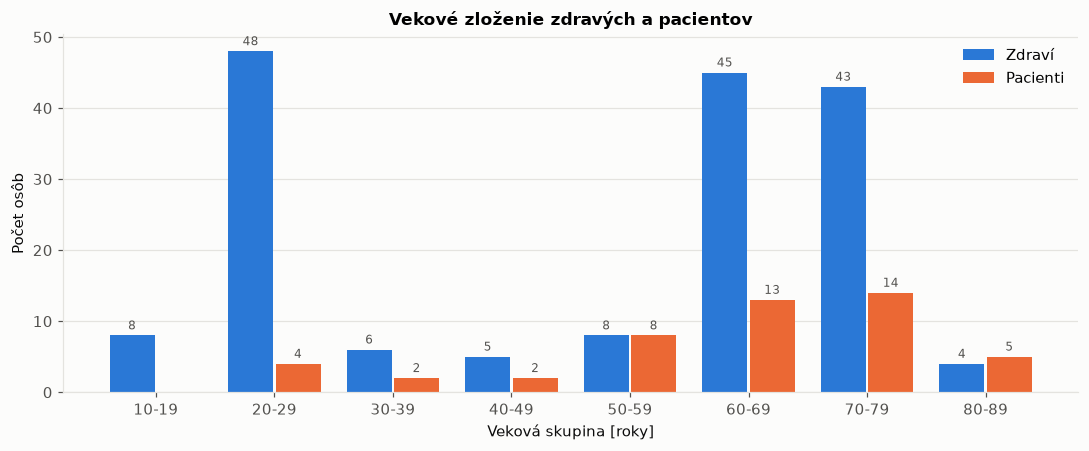

,Zdraví,Pacienti
počet osôb,167,48
vek – medián (Q1–Q3),64 (23–71),66 (56–74)
vek – rozsah,18–85,21–89
ženy / muži,108 / 59,20 / 28


In [3]:
histogram = T["age_histogram"]
x = np.arange(len(histogram))
fig, ax = plt.subplots(figsize=(10, 4.2))
for offset, group in zip((-0.2, 0.2), GROUPS):
    bars = ax.bar(x + offset, histogram[group], 0.38, color=GROUP_COLORS[group], label=SK_GROUP[group])
    ax.bar_label(bars, labels=[str(v) if v else "" for v in histogram[group]], padding=2, fontsize=8, color=MUTED)
ax.set_xticks(x, histogram["age_group"])
ax.set_xlabel("Veková skupina [roky]")
ax.set_ylabel("Počet osôb")
ax.set_title("Vekové zloženie zdravých a pacientov")
ax.grid(axis="x", visible=False)
ax.legend()
fig.tight_layout()
plt.show()

demo = T["demographics_by_group"].set_index("group")
table = pd.DataFrame({
    SK_GROUP[g]: {
        "počet osôb": int(demo.loc[g, "n_people"]),
        "vek – medián (Q1–Q3)": f"{demo.loc[g, 'age_median']:.0f} ({demo.loc[g, 'age_q1']:.0f}–{demo.loc[g, 'age_q3']:.0f})",
        "vek – rozsah": f"{demo.loc[g, 'age_min']:.0f}–{demo.loc[g, 'age_max']:.0f}",
        "ženy / muži": f"{demo.loc[g, 'n_female']} / {demo.loc[g, 'n_male']}",
    } for g in GROUPS})
display(table)

In [4]:
test = T["age_test"].iloc[0]
old = histogram.loc[histogram["age_group"].str[:1].astype(int) >= 5]
display(Markdown(
    f"**Záver:** zdraví majú medián veku {demo.loc['control', 'age_median']:.0f} rokov, pacienti "
    f"{demo.loc['patient', 'age_median']:.0f} rokov (Mann-Whitney p < 0,001). "
    f"{histogram.loc[histogram['age_group'] == '20-29', 'control'].iloc[0]} z {histogram['control'].sum()} zdravých je vo veku 20–29 rokov, "
    f"zatiaľ čo {old['patient'].sum()} zo {histogram['patient'].sum()} pacientov má 50 a viac rokov. Vo veku ≥ 50 rokov je "
    f"{old['control'].sum()} zdravých a {old['patient'].sum()} pacientov – len tu sú skupiny vekovo porovnateľné."))

**Záver:** zdraví majú medián veku 64 rokov, pacienti 66 rokov (Mann-Whitney p < 0,001). 48 z 167 zdravých je vo veku 20–29 rokov, zatiaľ čo 40 zo 48 pacientov má 50 a viac rokov. Vo veku ≥ 50 rokov je 100 zdravých a 40 pacientov – len tu sú skupiny vekovo porovnateľné.

## 2. Pacienti, ktorí slabo používajú jednu ruku

**Ukazovateľ:** pomer sily = priemerná sila prstov slabšej ruky / silnejšej ruky
(1 = obe ruky tlačia rovnako, 0 = jedna ruka netlačí vôbec).

**Kritérium:** pevný prah neexistuje, preto je referenciou skupina zdravých. Ruka je *slabo používaná*,
ak je pomer sily nižší ako u 97,5 % zdravých osôb.

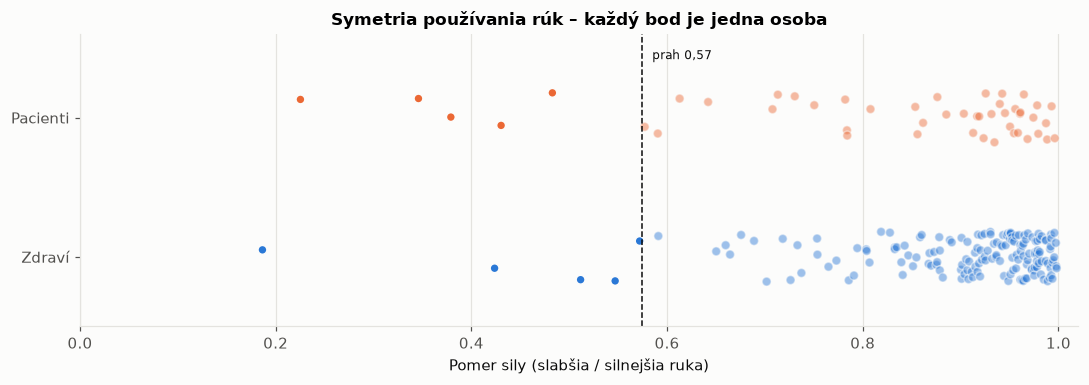

,pacient,vek,pohlavie,slabšia ruka,pomer sily,pomer kolísania
5,0IKB-27Y1,75,female,ľavá,0.23,0.12
6,3OUS-NI9J,82,female,ľavá,0.35,0.28
7,EJIT-XSEZ,76,male,pravá,0.38,0.85
8,ILHC-BZCP,73,female,pravá,0.43,0.35
9,W6JM-R0SG,58,female,pravá,0.48,0.66


In [5]:
activity = T["hand_activity"]
threshold = weak_hand_threshold(activity)
weak = weak_hand_patients(activity)
weak_patients = weak.loc[weak["group"] == "patient"]
weak_controls = weak.loc[weak["group"] == "control"]

fig, ax = plt.subplots(figsize=(10, 3.6))
rng = np.random.default_rng(0)
for row, group in enumerate(GROUPS):
    frame = activity.loc[activity["group"] == group]
    below = frame["force_ratio"] < threshold
    jitter = rng.uniform(-0.18, 0.18, len(frame))
    ax.scatter(frame["force_ratio"], row + jitter, s=34, color=GROUP_COLORS[group],
               alpha=np.where(below, 1.0, 0.45), edgecolor=SURFACE, linewidth=1, label=SK_GROUP[group])
ax.axvline(threshold, color=TEXT, linewidth=1, linestyle="--")
ax.text(threshold + 0.01, 1.42, f"prah {fmt(threshold, 2)}", fontsize=8, color=TEXT)
ax.set_yticks([0, 1], [SK_GROUP[g] for g in GROUPS])
ax.set_ylim(-0.5, 1.6)
ax.set_xlim(0, 1.02)
ax.set_xlabel("Pomer sily (slabšia / silnejšia ruka)")
ax.set_title("Symetria používania rúk – každý bod je jedna osoba")
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

display(weak_patients[["patient_id", "age", "gender", "weaker_hand", "force_ratio", "fluctuation_ratio"]]
        .assign(weaker_hand=lambda t: t["weaker_hand"].map(SK_HAND_SHORT))
        .rename(columns={"patient_id": "pacient", "age": "vek", "gender": "pohlavie",
                         "weaker_hand": "slabšia ruka", "force_ratio": "pomer sily",
                         "fluctuation_ratio": "pomer kolísania"}).round(2))

In [6]:
fluctuation_weak = weak_hand_patients(activity, metric="fluctuation_ratio")
fluctuation_patients = fluctuation_weak.loc[fluctuation_weak["group"] == "patient", "patient_id"]
display(Markdown(
    f"**Záver:** **{len(weak_patients)} zo {int(demo.loc["patient", "n_people"])} pacientov ({fmt(100 * len(weak_patients) / int(demo.loc["patient", "n_people"]))} %)** slabo používa jednu "
    f"ruku (pomer sily < {fmt(threshold, 2)}); slabšia je ľavá ruka u "
    f"{(weak_patients['weaker_hand'] == 'left').sum()} a pravá u {(weak_patients['weaker_hand'] == 'right').sum()} z nich. "
    f"Medzi zdravými sú pod prahom {len(weak_controls)} z {int(demo.loc["control", "n_people"])} osôb, čo zodpovedá definícii prahu (2,5 %). "
    f"Úplne neaktívnu ruku (pomer < 0,10) nemá nikto – najslabšia ruka dosahuje "
    f"{fmt(100 * activity['force_ratio'].min(), 0)} % sily druhej ruky.\n\n"
    f"*Doplnok:* ak sa namiesto sily použije kolísanie sily (ruka leží na snímačoch, ale aktívne nepracuje), "
    f"je pod prahom {len(fluctuation_patients)} pacientov; v oboch zoznamoch sú "
    f"{', '.join(sorted(set(weak_patients['patient_id']) & set(fluctuation_patients)))}."))

**Záver:** **5 zo 48 pacientov (10,4 %)** slabo používa jednu ruku (pomer sily < 0,57); slabšia je ľavá ruka u 2 a pravá u 3 z nich. Medzi zdravými sú pod prahom 5 z 167 osôb, čo zodpovedá definícii prahu (2,5 %). Úplne neaktívnu ruku (pomer < 0,10) nemá nikto – najslabšia ruka dosahuje 19 % sily druhej ruky.

*Doplnok:* ak sa namiesto sily použije kolísanie sily (ruka leží na snímačoch, ale aktívne nepracuje), je pod prahom 8 pacientov; v oboch zoznamoch sú 0IKB-27Y1, 3OUS-NI9J, ILHC-BZCP.

## 3. Tremor jednotlivých prstov

### Návrh analýzy

**Ukazovateľ tremoru:** priemerná amplitúda kolísania sily v pásme 4–15 Hz (`tremor_mean_amplitude`),
počítaná zvlášť pre každý prst, pokus a ruku. Pomalé kolísanie (0–4 Hz) je bežná korekcia sily,
ktorú má každý; rýchlejšie kmitanie (4–15 Hz) je tremor.

**Prečo prsty nemožno porovnať priamo:** prsty sa líšia už u zdravých – tlačia veľmi rozdielnou silou
(palec asi 7× viac ako malíček) a u jedného človeka má prst s väčšou silou spravidla aj väčšie kolísanie
(Spearmanovo ρ ≈ 0,6). Priame porovnanie by ukázalo hlavne tieto prirodzené rozdiely, nie tremor.

**Riešenie – porovnanie s normou toho istého prsta:** každý prst pacienta sa porovná s tým istým prstom
zdravých osôb vo veku ≥ 50 rokov (referenčná skupina). Sila prsta aj vlastnosti snímača sa tak vyrušia.

| Otázka | Metóda |
|---|---|
| A. Je tremor vôbec merateľný? | porovnanie so šumom nezaťaženého snímača (kalibračné merania) |
| B. Trasú sa niektoré prsty viac ako iné? | koľkokrát je tremor pacientov vyšší ako norma pre daný prst (pomer mediánov, 95 % interval spoľahlivosti) |
| C. Je rozdiel medzi prstami u jedného človeka? | z-skóre každého prsta voči norme; prst so z > 1,96 má vyšší tremor ako 97,5 % referenčných osôb; podľa počtu takých prstov je tremor **lokálny** (2–4 prsty) alebo **generalizovaný** (≥ 5 prstov) |

Neaktívne prsty (netlačia, priemerná sila < 0,002) sú vynechané – ich „tremor“ je len šum snímača.

### A. Je tremor prstov merateľný?

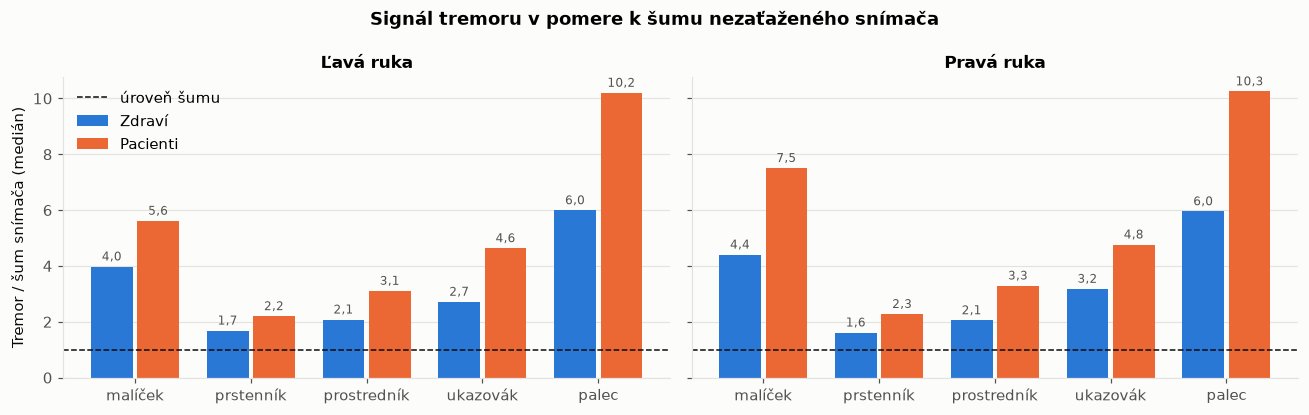

In [7]:
noise = T["finger_signal_to_noise"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
x = np.arange(len(FINGERS))
for ax, hand in zip(axes, HANDS):
    for offset, group in zip((-0.2, 0.2), GROUPS):
        values = noise.loc[(noise["hand"] == hand) & (noise["group"] == group)].set_index("finger_name")
        bars = ax.bar(x + offset, values["signal_to_noise"].reindex(FINGERS), 0.36,
                      color=GROUP_COLORS[group], label=SK_GROUP[group])
        ax.bar_label(bars, labels=[fmt(v) for v in values["signal_to_noise"].reindex(FINGERS)],
                     padding=2, fontsize=8, color=MUTED)
    ax.axhline(1, color=TEXT, linewidth=1, linestyle="--", label="úroveň šumu")
    ax.set_xticks(x, [SK_FINGER[f] for f in FINGERS])
    ax.set_title(SK_HAND[hand])
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Tremor / šum snímača (medián)")
axes[0].legend(loc="upper left")
fig.suptitle("Signál tremoru v pomere k šumu nezaťaženého snímača", fontweight="bold")
fig.tight_layout()
plt.show()

In [8]:
closest = noise.groupby("finger_name")["signal_to_noise"].median().idxmin()
ring = noise.loc[noise["finger_name"] == closest]
display(Markdown(
    f"**Záver:** tremor všetkých prstov je nad šumom snímača (medián {fmt(noise['signal_to_noise'].min())}–"
    f"{fmt(noise['signal_to_noise'].max())}× viac). Najbližšie k šumu je {SK_FINGER[closest]} – "
    f"{fmt(ring['percent_below_noise_p95'].min(), 0)}–{fmt(ring['percent_below_noise_p95'].max(), 0)} % jeho hodnôt "
    f"je na úrovni šumu, preto sú výsledky pre {SK_FINGER[closest]} menej spoľahlivé."))

**Záver:** tremor všetkých prstov je nad šumom snímača (medián 1,6–10,3× viac). Najbližšie k šumu je prstenník – 12–28 % jeho hodnôt je na úrovni šumu, preto sú výsledky pre prstenník menej spoľahlivé.

### B. Trasú sa niektoré prsty viac ako iné?

Vľavo je dôvod, prečo sa prsty nedajú porovnať priamo: už u zdravých sa prsty výrazne líšia silou
aj kolísaním (palec najviac; malíček má pri najmenšej sile pomerne veľké kolísanie). Vpravo je správne
porovnanie – koľkokrát je tremor pacientov vyšší ako norma zdravých (≥ 50 rokov) pre ten istý prst.
1 = rovnako ako zdraví.

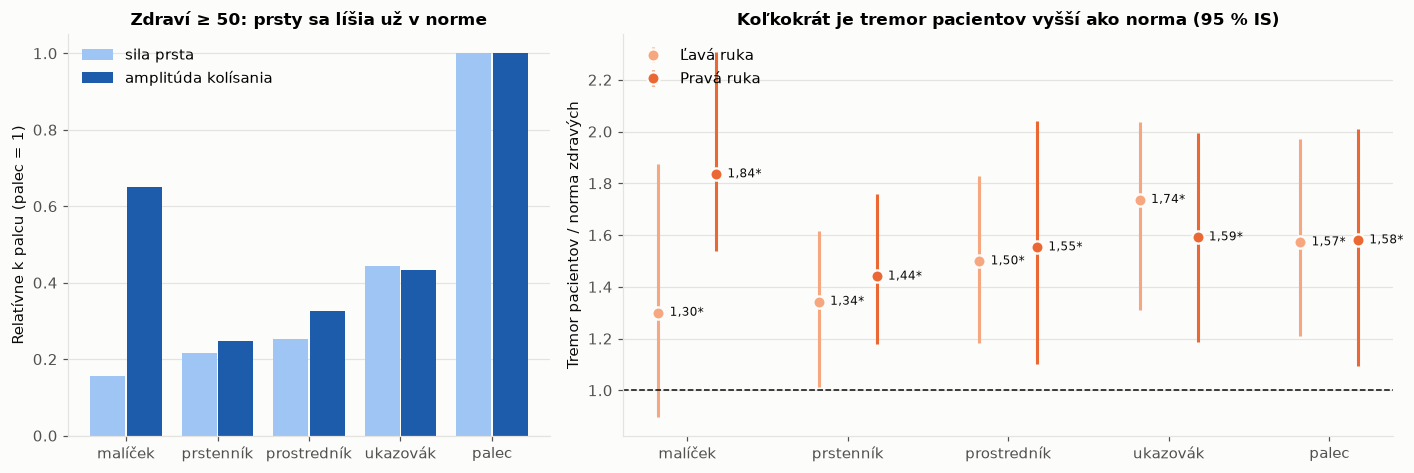

In [9]:
fingers_long = pd.read_csv(OUT / "features_by_person_finger.csv")
fingers_long = fingers_long.loc[fingers_long["step_id"].isin(wide["step_id"].unique())
                                & ~fingers_long["finger_inactive"].astype(bool)]
reference = fingers_long.loc[(fingers_long["group"] == "control") & (fingers_long["age"] >= REFERENCE_MIN_AGE)]
medians = reference.groupby("finger_name")[["mean_force", "tremor_mean_amplitude"]].median().reindex(FINGERS)

ratio = T["finger_ratio_to_reference"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
x = np.arange(len(FINGERS))
relative = medians / medians.loc["thumb"]
ax.bar(x - 0.2, relative["mean_force"], 0.38, color="#9ec5f4", label="sila prsta")
ax.bar(x + 0.2, relative["tremor_mean_amplitude"], 0.38, color=REFERENCE_COLOR, label="amplitúda kolísania")
ax.set_xticks(x, [SK_FINGER[f] for f in FINGERS])
ax.set_ylabel("Relatívne k palcu (palec = 1)")
ax.set_title("Zdraví ≥ 50: prsty sa líšia už v norme")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")

ax = axes[1]
for offset, hand in zip((-0.18, 0.18), HANDS):
    frame = ratio.loc[ratio["hand"] == hand].set_index("finger_name").reindex(FINGERS)
    positions = x + offset
    color = "#eb6834" if hand == "right" else "#f6a77f"
    ax.errorbar(positions, frame["ratio"], yerr=[frame["ratio"] - frame["ci_low"], frame["ci_high"] - frame["ratio"]],
                fmt="o", markersize=8, color=color, ecolor=color, elinewidth=2, capsize=0,
                markeredgecolor=SURFACE, markeredgewidth=1.5, label=SK_HAND[hand])
    for position, value, p in zip(positions, frame["ratio"], frame["p_holm"]):
        ax.text(position + 0.07, value, f"{fmt(value, 2)}{'*' if p < ALPHA else ''}", fontsize=8,
                color=TEXT, va="center")
ax.axhline(1, color=TEXT, linewidth=1, linestyle="--")
ax.set_xticks(x, [SK_FINGER[f] for f in FINGERS])
ax.set_ylabel("Tremor pacientov / norma zdravých")
ax.set_title("Koľkokrát je tremor pacientov vyšší ako norma (95 % IS)")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

In [10]:
significant = ratio.loc[ratio["p_holm"] < ALPHA]
top = ratio.nlargest(3, "ratio")
display(Markdown(
    f"**Záver:** prsty nemožno porovnať priamo, lebo sa líšia už u zdravých. "
    f"V porovnaní s normou pre ten istý prst majú pacienti vyšší tremor na **všetkých prstoch** "
    f"({fmt(ratio['ratio'].min(), 2)}–{fmt(ratio['ratio'].max(), 2)}× viac), štatisticky významne na "
    f"{len(significant)} z 10 prstov (* = p < 0,05 po Holmovej korekcii). "
    f"Najväčší nárast je na prstoch: "
    + ", ".join(f"{SK_FINGER[r.finger_name]} ({SK_HAND_SHORT[r.hand]}) {fmt(r.ratio, 2)}×" for r in top.itertuples())
    + ". Významný nárast: "
    + "; ".join(f"{SK_HAND_SHORT[h]} ruka – "
                + (", ".join(SK_FINGER[f] for f in FINGERS if f in set(significant.loc[significant['hand'] == h, 'finger_name']))
                   or "žiadny prst")
                for h in HANDS) + "."))

**Záver:** prsty nemožno porovnať priamo, lebo sa líšia už u zdravých. V porovnaní s normou pre ten istý prst majú pacienti vyšší tremor na **všetkých prstoch** (1,30–1,84× viac), štatisticky významne na 10 z 10 prstov (* = p < 0,05 po Holmovej korekcii). Najväčší nárast je na prstoch: malíček (pravá) 1,84×, ukazovák (ľavá) 1,74×, ukazovák (pravá) 1,59×. Významný nárast: ľavá ruka – malíček, prstenník, prostredník, ukazovák, palec; pravá ruka – malíček, prstenník, prostredník, ukazovák, palec.

### C. Je rozdiel medzi prstami u jedného človeka?

Každý riadok je jeden pacient, každý stĺpec jeden prst. Farba je z-skóre voči norme toho istého prsta
(červená = viac ako zdraví, modrá = menej). Bodka označuje zvýšený tremor (z > 1,96).
Šedá bunka = prst netlačil.

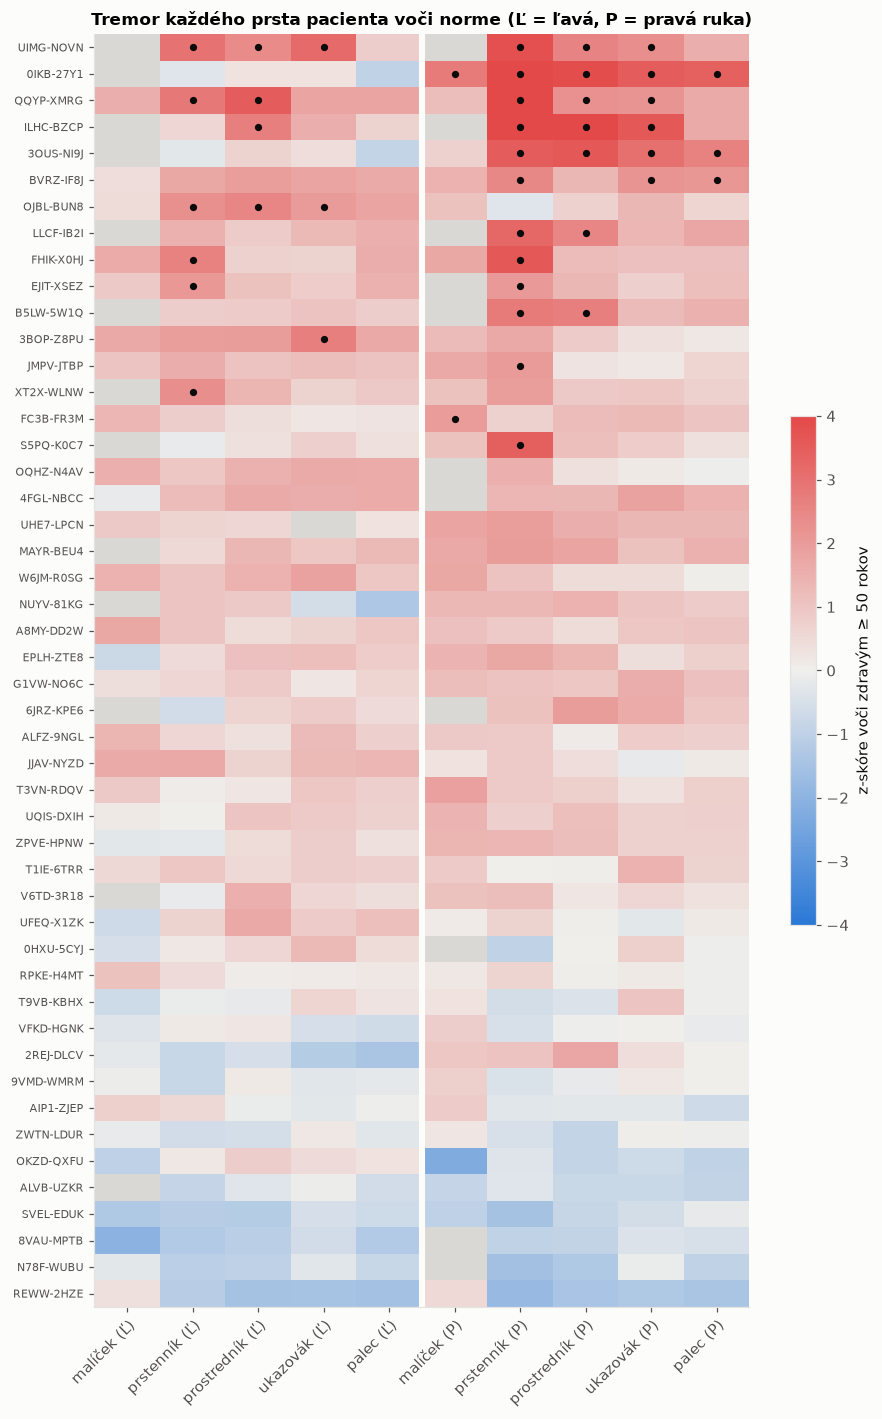

In [11]:
z = T["finger_z_scores"]
pattern = T["tremor_pattern"]
patients_z = z.loc[z["group"] == "patient"].assign(column=lambda t: t["hand"] + "_" + t["finger_name"])
columns = [f"{hand}_{finger}" for hand in HANDS for finger in FINGERS]
order = pattern.loc[pattern["group"] == "patient"].sort_values(["n_elevated", "median_z"], ascending=False)["patient_id"]
matrix = patients_z.pivot_table(index="patient_id", columns="column", values="z").reindex(index=order, columns=columns)

fig, ax = plt.subplots(figsize=(8.5, 13))
image = ax.imshow(matrix.clip(-4, 4), cmap=DIVERGING, vmin=-4, vmax=4, aspect="auto")
image.cmap.set_bad("#d9d8d4")
rows, cols = np.where(matrix.to_numpy() > ELEVATED_TREMOR_Z)
ax.scatter(cols, rows, s=14, color=TEXT)
ax.set_xticks(range(len(columns)), [f"{SK_FINGER[c.split('_')[1]]} ({SK_HAND_SHORT[c.split('_')[0]][0].upper()})"
                                    for c in columns], rotation=45, ha="right", rotation_mode="anchor")
ax.set_yticks(range(len(matrix)), matrix.index, fontsize=7)
ax.axvline(len(FINGERS) - 0.5, color=SURFACE, linewidth=4)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.4, label="z-skóre voči zdravým ≥ 50 rokov")
ax.set_title("Tremor každého prsta pacienta voči norme (Ľ = ľavá, P = pravá ruka)")
fig.tight_layout()
plt.show()

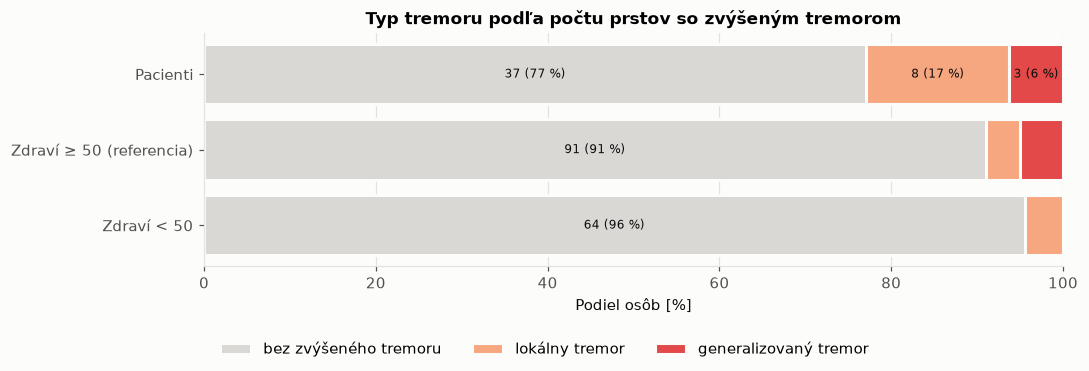

In [12]:
pattern["category"] = np.select(
    [pattern["group"] == "patient", pattern["is_reference"]],
    ["Pacienti", f"Zdraví ≥ {REFERENCE_MIN_AGE} (referencia)"], default=f"Zdraví < {REFERENCE_MIN_AGE}")
categories = ["Pacienti", f"Zdraví ≥ {REFERENCE_MIN_AGE} (referencia)", f"Zdraví < {REFERENCE_MIN_AGE}"]
labels = {"none": "bez zvýšeného tremoru", "localized": "lokálny tremor", "generalized": "generalizovaný tremor"}
shares = (pd.crosstab(pattern["category"], pattern["pattern"], normalize="index") * 100).reindex(
    index=categories, columns=list(labels), fill_value=0)
counts = pd.crosstab(pattern["category"], pattern["pattern"]).reindex(index=categories, columns=list(labels),
                                                                      fill_value=0)
colors = {"none": "#d9d8d4", "localized": "#f6a77f", "generalized": "#e34948"}
fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(categories))
for key in labels:
    ax.barh(categories, shares[key], left=left, color=colors[key], edgecolor=SURFACE, linewidth=2, label=labels[key])
    for i, (share, count) in enumerate(zip(shares[key], counts[key])):
        if share >= 6:
            ax.text(left[i] + share / 2, i, f"{count} ({fmt(share, 0)} %)", ha="center", va="center", fontsize=8,
                    color=TEXT)
    left += shares[key].to_numpy()
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Podiel osôb [%]")
ax.set_title("Typ tremoru podľa počtu prstov so zvýšeným tremorom")
ax.grid(axis="y", visible=False)
handles, legend_labels = ax.get_legend_handles_labels()
fig.legend(handles, legend_labels, ncol=3, loc="lower center")
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()

In [13]:
p = pattern.loc[pattern["group"] == "patient"]
elevated_share = (patients_z.dropna(subset=["z"]).assign(e=lambda t: t["z"] > ELEVATED_TREMOR_Z)
                  .groupby(["hand", "finger_name"])["e"].mean() * 100)
most = elevated_share.nlargest(3)
display(Markdown(
    f"**Záver:** u {(p['pattern'] != 'none').sum()} zo {len(p)} pacientov ({fmt(100 * (p['pattern'] != 'none').mean(), 0)} %) "
    f"je tremor zvýšený aspoň na {LOCALIZED_MIN_FINGERS} prstoch: **{(p['pattern'] == 'localized').sum()} má lokálny tremor** "
    f"(niekoľko prstov, ostatné v norme) a **{(p['pattern'] == 'generalized').sum()} generalizovaný** (≥ {GENERALIZED_MIN_FINGERS} prstov). "
    f"U zdravých je to {(pattern.loc[pattern['group'] == 'control', 'pattern'] != 'none').sum()} z {(pattern['group'] == 'control').sum()}. "
    f"Tremor teda u väčšiny postihnutých pacientov **nie je rovnaký na všetkých prstoch** – zvyšuje sa len na "
    f"niektorých. Najčastejšie zvýšený je tremor na prstoch: "
    + ", ".join(f"{SK_FINGER[f]} ({SK_HAND_SHORT[h]}) {fmt(v, 0)} % pacientov" for (h, f), v in most.items())
    + ".\n\n*Poznámka:* referenčná skupina definuje normu, preto je jej vlastný podiel optimistický; "
    "rozdiel pacientov oproti mladším zdravým (< 50) ukazuje, že výsledok nie je spôsobený len výberom referencie."))

**Záver:** u 11 zo 48 pacientov (23 %) je tremor zvýšený aspoň na 2 prstoch: **8 má lokálny tremor** (niekoľko prstov, ostatné v norme) a **3 generalizovaný** (≥ 5 prstov). U zdravých je to 12 z 167. Tremor teda u väčšiny postihnutých pacientov **nie je rovnaký na všetkých prstoch** – zvyšuje sa len na niektorých. Najčastejšie zvýšený je tremor na prstoch: prstenník (pravá) 25 % pacientov, prostredník (pravá) 15 % pacientov, prstenník (ľavá) 12 % pacientov.

*Poznámka:* referenčná skupina definuje normu, preto je jej vlastný podiel optimistický; rozdiel pacientov oproti mladším zdravým (< 50) ukazuje, že výsledok nie je spôsobený len výberom referencie.

### Príklad: spektrum prstov

Časovo spriemerované spektrum (pokus 2 – prvý je skúšobný; pásmo 4–15 Hz) pacienta s najvýraznejším vrcholom tremoru
(medián výraznosti vrcholu cez prsty) a typickej zdravej osoby z referenčnej skupiny. Bod = nájdený vrchol.
Zdravá osoba nemá výrazný vrchol – spektrum s frekvenciou plynulo klesá. Ak má pacient vrchol na rovnakej
frekvencii na všetkých prstoch, tremor má spoločný zdroj (celá ruka), nie jednotlivé prsty.

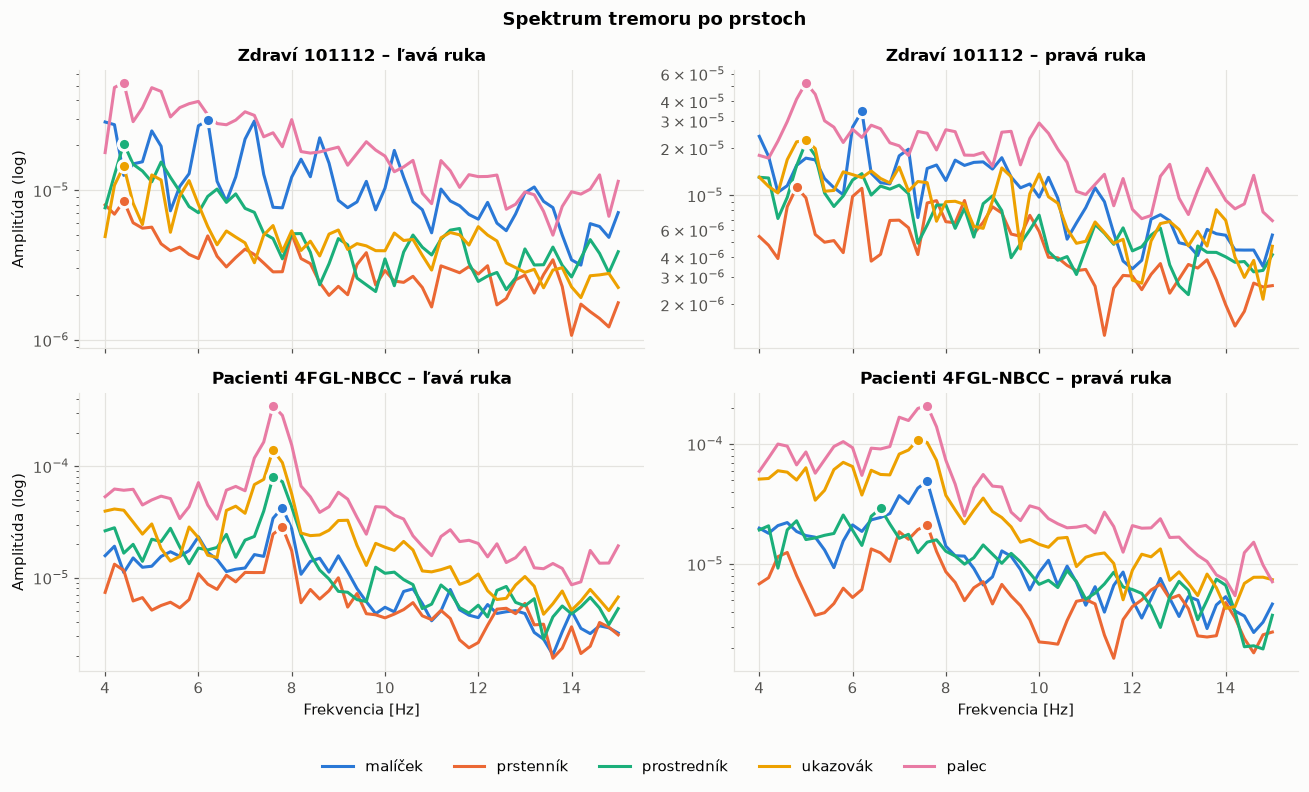

In [14]:
# The patient whose fingers show the most distinct tremor peak (median prominence over fingers).
prominence = fingers_long.groupby(["patient_id", "group"])["tremor_peak_prominence"].median().reset_index()
patient_id = prominence.loc[prominence["group"] == "patient"].nlargest(1, "tremor_peak_prominence")["patient_id"].iloc[0]
reference_people = pattern.loc[pattern["is_reference"]].sort_values("median_z")
control_id = reference_people.iloc[len(reference_people) // 2]["patient_id"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for row, (person, group) in enumerate(((control_id, "control"), (patient_id, "patient"))):
    record = attempts.loc[(attempts["patient_id"] == person) & attempts["step_id"].isin(wide["step_id"])].iloc[0]
    data = load_measurement_data(resolve_project_path(record["file_path"]), CROP_START_S, CROP_END_S)
    data = data.loc[(data["attempt"] == 2) & (data["segment"] == 1)]  # attempt 1 is the practice attempt
    peaks = attempts.loc[(attempts["file_path"] == record["file_path"]) & (attempts["attempt"] == 2)]
    for col, hand in enumerate(HANDS):
        ax = axes[row, col]
        for color, (number, finger) in zip(FINGER_COLORS, enumerate(FINGERS, start=1)):
            frequencies, _, magnitude = compute_spectrogram(data[f"{hand}_sensor_{number}"].to_numpy())
            band = band_mask(frequencies, TREMOR_BAND)
            ax.plot(frequencies[band], magnitude[band].mean(axis=1), color=color, linewidth=2, label=SK_FINGER[finger])
            peak = peaks.loc[(peaks["hand"] == hand) & (peaks["finger"] == number)].iloc[0]
            if np.isfinite(peak["tremor_peak_frequency_hz"]):
                ax.scatter(peak["tremor_peak_frequency_hz"], peak["tremor_peak_amplitude"], s=64, color=color,
                           edgecolor=SURFACE, linewidth=2, zorder=3)
        ax.set_yscale("log")
        ax.set_title(f"{SK_GROUP[group]} {person} – {SK_HAND[hand].lower()}")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.03))
for ax in axes[1]:
    ax.set_xlabel("Frekvencia [Hz]")
for ax in axes[:, 0]:
    ax.set_ylabel("Amplitúda (log)")
fig.suptitle("Spektrum tremoru po prstoch", fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## Zhrnutie

In [15]:
by_hand = ratio.groupby("hand")["ratio"].mean()
stronger_hand = "pravej" if by_hand["right"] > by_hand["left"] else "ľavej"
n_reference = int(pattern["is_reference"].sum())
display(Markdown(f"""
1. **Vek:** pacienti sú starší (medián {demo.loc['patient', 'age_median']:.0f} vs. {demo.loc['control', 'age_median']:.0f} rokov);
   porovnateľné sú len osoby vo veku ≥ 50 rokov.
2. **Slabo používaná ruka:** {len(weak_patients)} zo {int(demo.loc["patient", "n_people"])} pacientov ({fmt(100 * len(weak_patients) / int(demo.loc["patient", "n_people"]))} %) má pomer sily rúk
   nižší ako 97,5 % zdravých; úplne neaktívnu ruku nemá nikto.
3. **Tremor prstov:**
   * prsty nemožno porovnávať priamo, lebo sa líšia už u zdravých (sila, kolísanie) – každý prst sa porovnáva s normou pre ten istý prst;
   * pacienti majú vyšší tremor na všetkých prstoch ({fmt(ratio['ratio'].min(), 2)}–{fmt(ratio['ratio'].max(), 2)}× norma),
     výraznejšie na {stronger_hand} ruke (priemerne {fmt(by_hand.max(), 2)}× vs. {fmt(by_hand.min(), 2)}×);
   * u {(p['pattern'] != 'none').sum()} pacientov je tremor zvýšený na viacerých prstoch, prevažne **lokálne**
     ({(p['pattern'] == 'localized').sum()} pacientov), generalizovane len u {(p['pattern'] == 'generalized').sum()}.

**Obmedzenia:** rôzne `step_id` pre zdravých a pacientov, referenčná skupina {n_reference} zdravých ≥ 50 rokov (väčšina z meracieho centra),
neoverené poradie prstov na snímačoch.
"""))


1. **Vek:** pacienti sú starší (medián 66 vs. 64 rokov);
   porovnateľné sú len osoby vo veku ≥ 50 rokov.
2. **Slabo používaná ruka:** 5 zo 48 pacientov (10,4 %) má pomer sily rúk
   nižší ako 97,5 % zdravých; úplne neaktívnu ruku nemá nikto.
3. **Tremor prstov:**
   * prsty nemožno porovnávať priamo, lebo sa líšia už u zdravých (sila, kolísanie) – každý prst sa porovnáva s normou pre ten istý prst;
   * pacienti majú vyšší tremor na všetkých prstoch (1,30–1,84× norma),
     výraznejšie na pravej ruke (priemerne 1,60× vs. 1,49×);
   * u 11 pacientov je tremor zvýšený na viacerých prstoch, prevažne **lokálne**
     (8 pacientov), generalizovane len u 3.

**Obmedzenia:** rôzne `step_id` pre zdravých a pacientov, referenčná skupina 100 zdravých ≥ 50 rokov (väčšina z meracieho centra),
neoverené poradie prstov na snímačoch.
